<a href="https://colab.research.google.com/github/cmauriciocrescente-upc/Dataset-en-Colab/blob/main/Bias_vs_Varianza.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bias vs Varianza

Fuente:https://medium.com/@nicolasarrioja/gu%C3%ADa-definitiva-a-bias-variance-tradeoff-94fb5c118d0f


Uno de los conceptos más importantes para poder obtener un óptimo resultado de nuestro modelo es el Bias-Variance tradeoff, por lo que es importante comprenderlo.

Este concepto también es conocido como Compensación Bias-Varianza.

Cuando creamos un modelo de machine learning deseamos que sea lo más eficiente posible para obtener los mejores resultados, pero para lograrlo tenemos que lograr un balance entre el Bias y Variance. Esto nos lleva a la compensación Bias-Variance.

Tanto Bias como Variance son errores en nuestro modelo y buscamos reducirlos, pero no resulta tan sencillo. Cuando logramos reducir Bias notaremos que Variance incrementa, si reducimos variance entonces Bias incrementa. Esto nos lleva a una situación de balance donde ambos deben de ser lo mas pequeños posibles.


## Bias: Es la diferencia entre la predicción esperada de nuestro modelo y los valores verdaderos.

El Bias o sesgo en un modelo de machine learning es muy fácil de entender, simplemente es un tipo de error que indica la diferencia que existe entre la predicción del modelo y el valor actual. Si lo vemos desde la perspectiva de la estadística es la tendencia a sobrestimar o subestimar un parámetro. Si el modelo tiene un Bias alto significa que le presta poca atención a los datos y sobre simplifica el modelo. Esto nos lleva a tener un error alto tanto en training como en test.

Para usar los términos más formales de sesgo y varianza, supongamos que tenemos un estimador puntual $\hat{θ}$ de algún parámetro o función $θ$. Entonces, el sesgo comúnmente se define como la diferencia entre el valor esperado del estimador y el parámetro que queremos estimar:

$$ Bias = E[\hat{θ}]- θ $$





## Variance: Se refiere a la cantidad que la estimación de la función objetivo cambiará si se utiliza diferentes datos de entrenamiento.

Variance o varianza también se considera un error en el modelo de machine learning que tenemos. Este error lo podemos entender como que tan sensible es nuestro modelo a los datos. Si tenemos exceso de sensibilidad el modelo puede creer ver patrones que realmente no existen ahí. En el contexto de estadística es una medida de dispersión de los datos, es la distancia de cada variable a la media de todas las variables. Si tenemos un valor de Variance alto esto significa que el modelo le presta mucha atención a los datos de entrenamiento y no va a generalizar bien en datos que no ha visto. Esto lo podemos ver cuando en el entrenamiento el modelo funciona muy bien pero tiene mucho error en el test.

$$ Variance = E[(E[\hat{θ}]- \hat{θ})^2] $$






No es posible seleccionar uno sobre otro para reducir, ya que si nos concentramos en uno en particular el modelo puede generar overfit o underfit. En ambos casos nuestro modelo va a tener problemas. La única opción que tenemos es encontrar el punto donde ambos puedan ser lo más pequeños posible.

Tenemos que tomar en cuenta que existe otro tipo de error que no puede ser reducido al crear modelos, sin importar que tan buenos sean. Este error se conoce como error irreductible y simplemente es un medida de la cantidad de ruido que tenemos en nuestros datos. El error total el modelo será:

http://rasbt.github.io/mlxtend/user_guide/evaluate/bias_variance_decomp/


$$ Error = [Bias]^2 + Varianza + ErrorIrreductible$$




Podemos entender esto más fácilmente en la siguiente imagen.


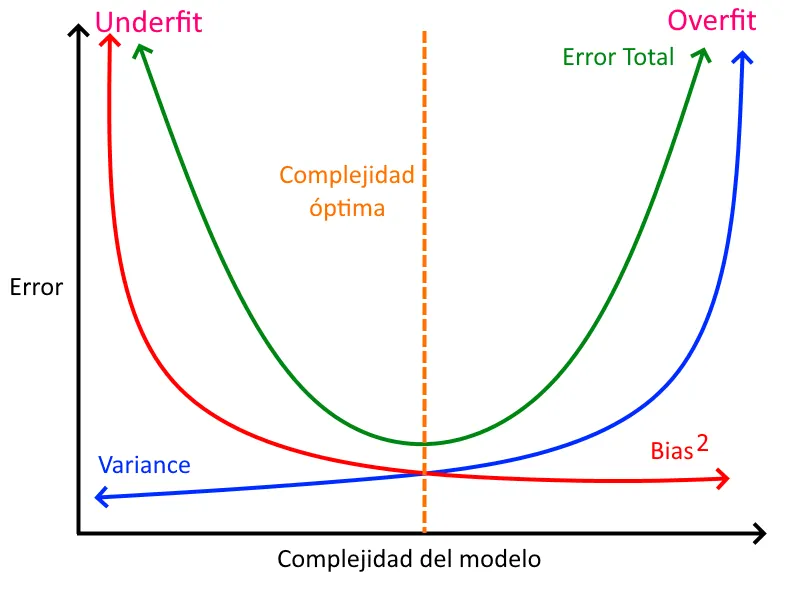

Una imagen clásica para explicar este concepto consiste de cuatro blancos (dianas) donde podemos ver el efecto de Bias y Variance.

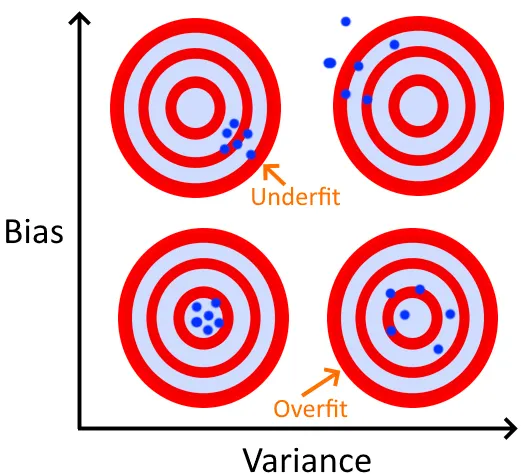

Al observar la imagen podemos entender el comportamiento de cada tipo de error. Si el Bias es pequeño nos encontramos cerca del centro, pero si se incrementa nos alejamos de él. Con la varianza podemos observar que si el valor es pequeño los puntos se encuentran cercanos entre sí, pero al aumentar los puntos se encuentran dispersos. Solamente si bajamos el error en ambos podemos tener los mejores resultados.

Al bajar el Bias y Variance reducimos el error total del modelo, lo que nos acerca a tener un modelo óptimo. Al lograr esto tenemos un modelo que no es muy complejo o muy sencillo. ¿Por qué es esto importante? Si tenemos un modelo complejo tendemos a tener overfitting, pero si tenemos un modelo sencillo lo que lograremos es underfitting.



La curva verde nos indica como se modifica el valor del error al cambiar el valor de Bias o de Variance. Si observamos hay un punto donde el error total del modelo es más bajo. En ese punto el valor de Bias y Variance nos permite tener la complejidad óptima del modelo, lo que significa que tendremos el menor error. Todo este concepto es la compensación Bias-Variance o Bias-Variance tradeoff.



Es importante conocer que puede producir el underfitting y el overfitting ahora que ya tenemos los conceptos de Bias y Variance claros.

## ¿Cuando sucede el underfitting?

Puede suceder cuando tenemos una cantidad baja de parámetros en el modelo y no se puede capturar la esencia de los datos de entrenamiento.

Cuando tenemos un Bias alto y Variance bajo.

También puede ocasionarse cuando tenemos tan pocos datos que no se puede construir un modelo adecuado.

Si intentamos construir un modelo lineal cuando los datos no son lineales también surge este problema.




## ¿Cuando sucede el overfitting?

Cuando tenemos muchos predictores o parámetros lo cual ocasiona que se capture el ruido junto con el patrón de los datos. Esto hace que el modelo se ajuste mucho a los datos de entrenamiento perdiendo generalidad para poder trabajar con datos no vistos.

Si tenemos un valor bajo de Bias y alto de Variance.

Si tenemos un modelo muy complejo para representar datos más sencillos.

Observemos este comportamiento en un modelo real.

![imagen.png](attachment:imagen.png)

![imagen.png](attachment:imagen.png)

El valor de P indica el grado del polinomio que estamos usando para crear el modelo. Podemos observar que para P=1 y P=2, el modelo no se ajusta bien a los datos, tenemos underfitting. En el caso de P=11 hasta P=15, el modelo trata de exagerar el ajuste a los datos lo que nos indica overfitting. Los demás modelos parecen tener un ajuste adecuado, pero ¿cuál es el mejor?, eso lo podemos saber si observamos el error total de todos los modelos.

![imagen.png](attachment:imagen.png)

## Como atender estos errores

https://colab.research.google.com/github/goodboychan/chans_jupyter/blob/master/_notebooks/2020-06-03-02-The-Bias-Variance-Tradeoff.ipynb


## Ejemplo en regresión lineal

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from random import randint
from math import pi as PI
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

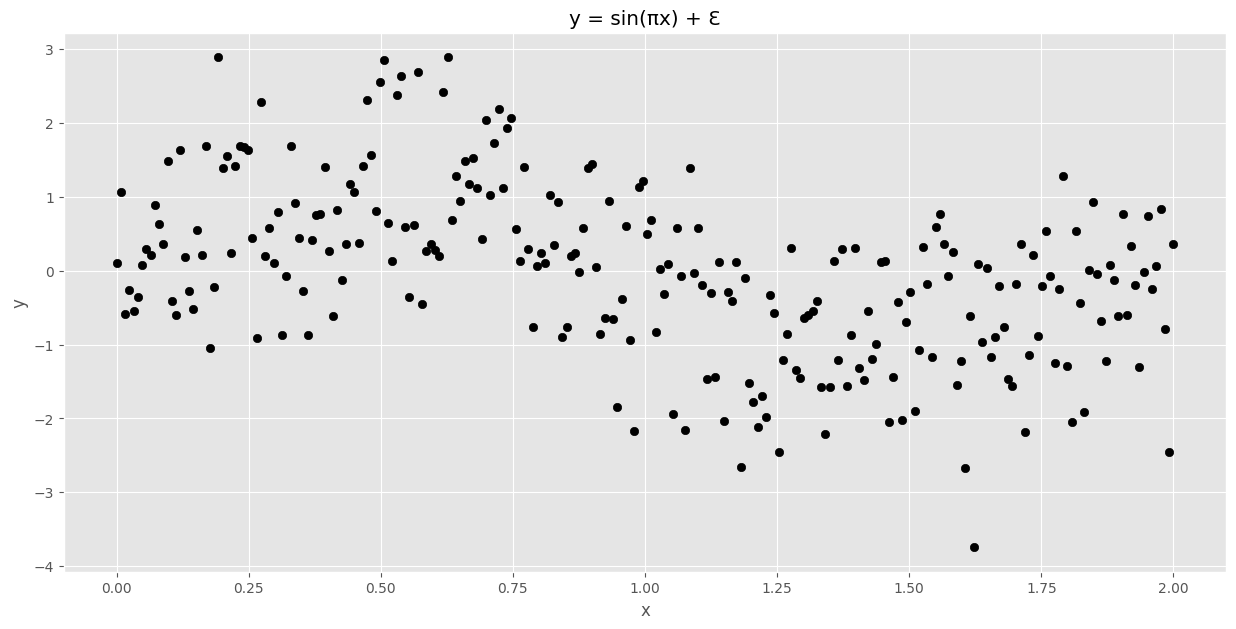

In [7]:

plt.style.use('ggplot')

# for reproducibility across different runs, one may set a seed as follows:
# np.random.seed(42)

# number of observations
NUM_OBS = 250

# predictors
x = np.linspace(0, 2, num = NUM_OBS)
# noise
eps = np.random.normal(0, 1, NUM_OBS)
# outcome
y = np.sin(PI*x) + eps

fig = plt.figure(figsize=(15,7))
ax = plt.axes()
ax.set_title('y = sin(πx) + Ɛ')
ax.set_xlabel("x")
ax.set_ylabel("y")

ax.scatter(x, y, c = 'k')

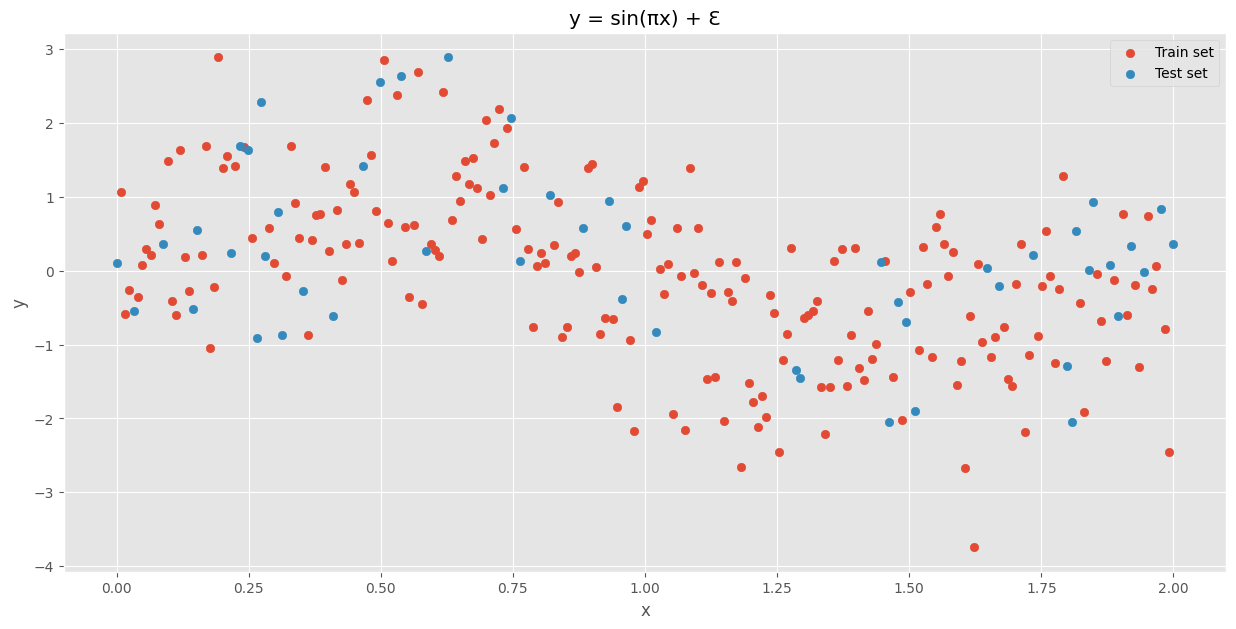

In [8]:
x_train, x_test, y_train, y_test = train_test_split(x,
                                                    y,
                                                    test_size = 0.2,
                                                    random_state = 1)

fig = plt.figure(figsize = (15,7))
ax = plt.axes()
ax.set_title('y = sin(πx) + Ɛ')
ax.set_xlabel("x")
ax.set_ylabel("y")

ax.scatter(x_train, y_train, label = "Train set")
ax.scatter(x_test, y_test, label = "Test set")
ax.legend()

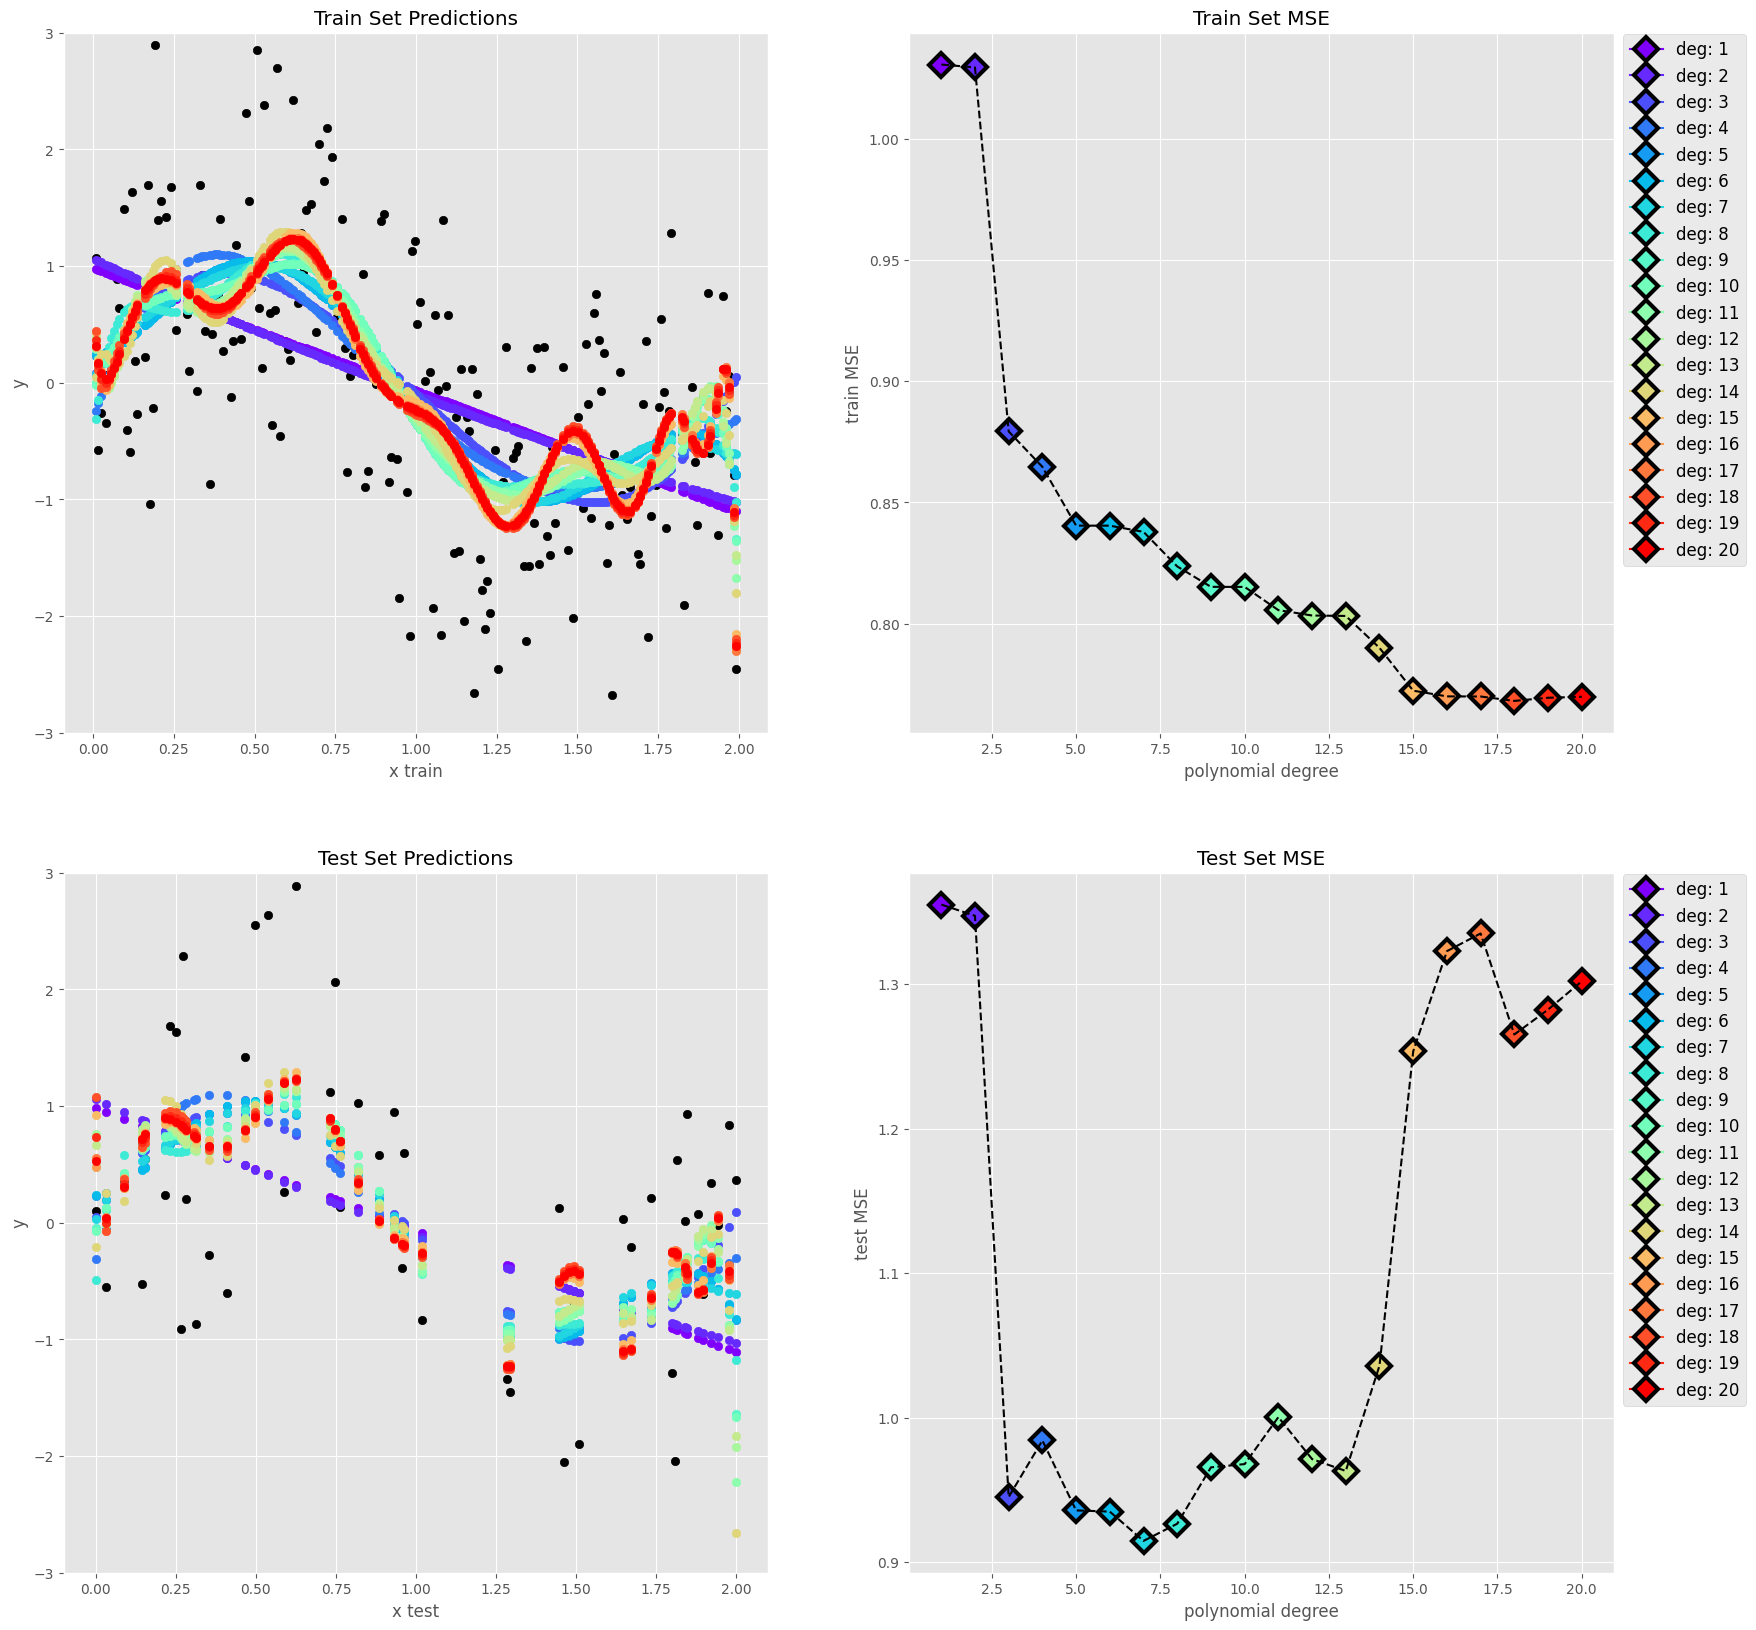

In [9]:
# number of polynomial models to investigate
NUM_MODELS = 20

colors = iter(plt.cm.rainbow(np.linspace(0, 1, NUM_MODELS)))

fig, axs = plt.subplots(2, 2, figsize = (20,20))

axs[0, 0].set_title('Train Set Predictions')
axs[1, 0].set_title('Test Set Predictions')
axs[0, 1].set_title('Train Set MSE')
axs[1, 1].set_title('Test Set MSE')

axs[0, 0].set_xlabel("x train")
axs[0, 0].set_ylabel("y")
axs[0, 0].set_ylim([-3, 3])

axs[1, 0].set_xlabel("x test")
axs[1, 0].set_ylabel("y")
axs[1, 0].set_ylim([-3, 3])

axs[0, 1].set_xlabel("polynomial degree")
axs[0, 1].set_ylabel("train MSE")

axs[1, 1].set_xlabel("polynomial degree")
axs[1, 1].set_ylabel("test MSE")

axs[0,0].scatter(x_train, y_train, c = 'k', label = "y train")
axs[1,0].scatter(x_test, y_test, c = 'k', label = "y test")

train_mse = []
test_mse = []

for k in range(0, NUM_MODELS):
    c = next(colors)

    # k-th degree polynomial coefficients
    fit_coeff = np.polyfit(x_train, y_train, deg = k+1)

    # train and test k-th degree polynomial fit
    y_train_pred = np.polyval(fit_coeff, x_train)
    y_test_pred = np.polyval(fit_coeff, x_test)

    # plot train and test k-th degree polynomial fit

    axs[0,0].scatter(x_train,
                   y_train_pred,
                   color = c,
                   label = "deg: {}".format(k+1))

    axs[1,0].scatter(x_test,
                   y_test_pred,
                   color = c,
                   label = "deg: {}".format(k+1))


    # train and test MSE of k-th degree polynomial fit
    iter_train_mse = mean_squared_error(y_train_pred, y_train)
    iter_test_mse = mean_squared_error(y_test_pred, y_test)

    train_mse.append(iter_train_mse)
    test_mse.append(iter_test_mse)

    # plot train and test MSE of k-th degree polynomial fit

    axs[0,1].plot(k+1,
                iter_train_mse,
                color = c,
                label = "deg: {}".format(k+1),
                marker = 'D',
                markersize = 12,
                markeredgecolor = 'black',
                markeredgewidth = 3)

    axs[1,1].plot(k+1,
                iter_test_mse,
                color = c,
                label = "deg: {}".format(k+1),
                marker = 'D',
                markersize = 12,
                markeredgecolor = 'black',
                markeredgewidth = 3)


# plot dashed line to interpolate MSE measures
axs[0,1].plot(range(1,NUM_MODELS+1), train_mse, 'k--')
axs[1,1].plot(range(1,NUM_MODELS+1), test_mse, 'k--')

# draw legends
axs[0,1].legend(loc = "upper right", bbox_to_anchor = (1.2, 1.01), prop = {'size': 12})
axs[1,1].legend(loc = "upper right", bbox_to_anchor = (1.2, 1.01), prop = {'size': 12})

In [10]:
print("Best fit polynomial degree: ", test_mse.index(min(test_mse)))

Best fit polynomial degree:  6


In [11]:
from mlxtend.evaluate import bias_variance_decomp
from sklearn.tree import DecisionTreeRegressor
from mlxtend.data import boston_housing_data
from sklearn.model_selection import train_test_split


#X_train, X_test, y_train, y_test = train_test_split(x_train, y_train,
#                                                    test_size=0.3,
#                                                    random_state=123,
#                                                    shuffle=True)



tree_regressor = DecisionTreeRegressor(random_state=123)

avg_expected_loss, avg_bias, avg_var = bias_variance_decomp(
        tree_regressor, x_train.reshape(-1,1), y_train, x_test.reshape(-1,1), y_test,
        loss='mse',
        random_seed=123)

print('Average expected loss: %.3f' % avg_expected_loss)
print('Average bias: %.3f' % avg_bias)
print('Average variance: %.3f' % avg_var)

Average expected loss: 1.645
Average bias: 1.303
Average variance: 0.343


In [14]:
tree_regressor.get_params()

{'ccp_alpha': 0.0,
 'criterion': 'squared_error',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 123,
 'splitter': 'best'}

In [15]:
from mlxtend.evaluate import bias_variance_decomp
from sklearn.tree import DecisionTreeRegressor
from mlxtend.data import boston_housing_data
from sklearn.model_selection import train_test_split


X, y = boston_housing_data()
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.3,
                                                    random_state=123,
                                                    shuffle=True)



tree_otro = DecisionTreeRegressor(random_state=123)

avg_expected_loss, avg_bias, avg_var = bias_variance_decomp(
        tree_otro, X_train, y_train, X_test, y_test,
        loss='mse',
        random_seed=123)

print('Average expected loss: %.3f' % avg_expected_loss)
print('Average bias: %.3f' % avg_bias)
print('Average variance: %.3f' % avg_var)

Average expected loss: 31.536
Average bias: 14.096
Average variance: 17.440


## Ejemplo en regresión: ajustando polinomios a datos polinómicos

Para ver el compromiso **Bias-Variance** en la práctica, vamos a generar datos a partir de una
función que **nosotros conocemos**, y a ella le sumamos ruido aleatorio:

$$ y = f(x) + \varepsilon \qquad con \qquad f(x) = 0.5x^3 - 2x^2 + x + 3 \qquad y \qquad \varepsilon \sim N(0, \sigma^2) $$

- $f(x)$ es un **polinomio de grado 3**: es la "verdad" que el modelo no conoce.
- $\varepsilon$ es el **error irreducible** (ruido): ningún modelo puede predecirlo.

Después ajustaremos modelos polinómicos de **grado 1 a 15** y veremos qué pasa:

| Grado del modelo | Qué esperamos | Diagnóstico |
|---|---|---|
| 1 – 2 | Muy simple para una curva cúbica | **Underfitting** (alto bias) |
| 3 | Coincide con la función real | **Ajuste adecuado** |
| 10 – 15 | Demasiado flexible, aprende el ruido | **Overfitting** (alta varianza) |

> Como conocemos el grado verdadero (3), podemos comprobar si el análisis de error lo detecta.

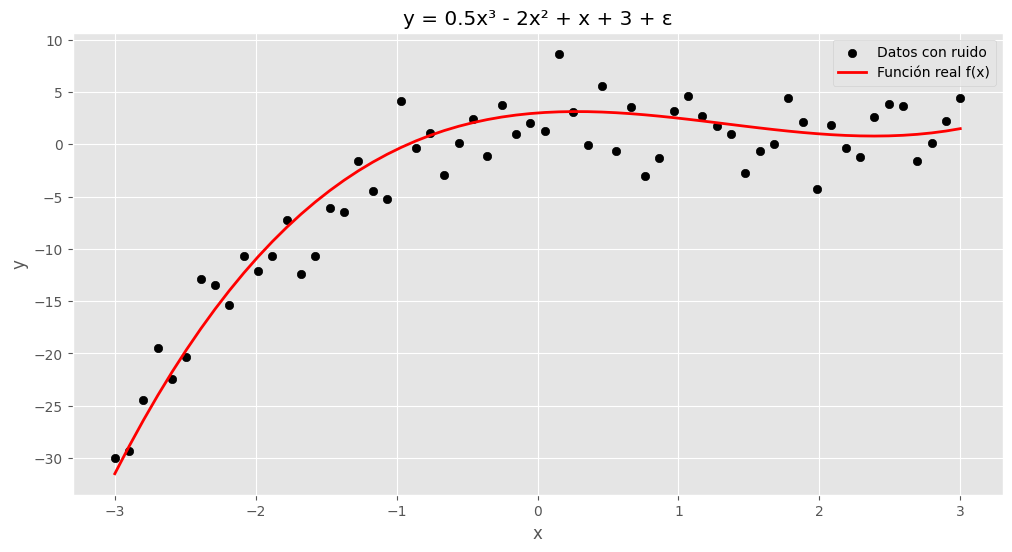

In [16]:
import numpy as np                                      # operaciones numéricas y generación de datos aleatorios
import matplotlib.pyplot as plt                         # gráficos
from sklearn.metrics import mean_squared_error          # métrica de error: error cuadrático medio (MSE)
from sklearn.model_selection import train_test_split    # para separar datos de entrenamiento y de prueba
import warnings                                         # para controlar los avisos de Python

warnings.filterwarnings("ignore")   # polyfit avisa (RankWarning) con grados altos; lo silenciamos porque es esperable
plt.style.use('ggplot')             # estilo visual de los gráficos
np.random.seed(42)                  # fija la semilla: los resultados son reproducibles en cada ejecución

NUM_OBS = 60                        # cantidad de observaciones (pocas, para que el overfitting se note)
SIGMA = 3.0                         # desvío estándar del ruido (su cuadrado, SIGMA**2, es el error irreducible)

def f_verdadera(x):
    """Función real que genera los datos (polinomio de grado 3)."""
    return 0.5 * x**3 - 2 * x**2 + x + 3    # 0.5x³ - 2x² + x + 3

x = np.linspace(-3, 3, NUM_OBS)             # 60 valores de x equiespaciados entre -3 y 3
eps = np.random.normal(0, SIGMA, NUM_OBS)   # ruido gaussiano: media 0, desvío SIGMA
y = f_verdadera(x) + eps                    # variable objetivo = función real + ruido

fig = plt.figure(figsize=(12, 6))                       # crea la figura con tamaño 12x6 pulgadas
ax = plt.axes()                                         # crea los ejes
ax.set_title('y = 0.5x³ - 2x² + x + 3 + ε')             # título del gráfico
ax.set_xlabel("x")                                      # etiqueta del eje x
ax.set_ylabel("y")                                      # etiqueta del eje y
ax.scatter(x, y, c='k', label='Datos con ruido')        # puntos observados (lo que el modelo "ve")
ax.plot(x, f_verdadera(x), 'r-', lw=2, label='Función real f(x)')  # curva verdadera (lo que el modelo "debe descubrir")
ax.legend()                                             # muestra la leyenda
plt.show()                                              # dibuja el gráfico

### Separación en entrenamiento y prueba

Dividimos los datos en dos grupos:

- **Train (80%)**: el modelo aprende con estos datos.
- **Test (20%)**: datos que el modelo **nunca vio**; sirven para medir qué tan bien generaliza.

Un modelo que memoriza el set de entrenamiento tendrá un error de train muy bajo, pero un error
de test alto. Esa **brecha entre ambos errores** es la señal clásica de overfitting.

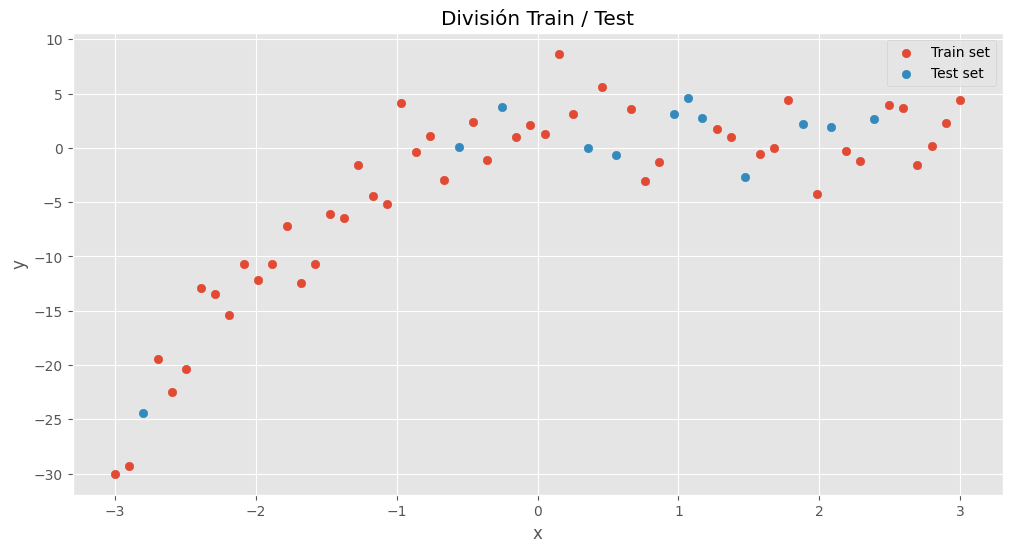

Observaciones de entrenamiento: 48 | de prueba: 12


In [17]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,                  # datos completos a dividir
    test_size=0.2,         # 20% para test, 80% para train
    random_state=1         # semilla para que la división sea siempre la misma
)

fig = plt.figure(figsize=(12, 6))                           # nueva figura
ax = plt.axes()                                             # ejes
ax.set_title('División Train / Test')                       # título
ax.set_xlabel("x")                                          # etiqueta eje x
ax.set_ylabel("y")                                          # etiqueta eje y
ax.scatter(x_train, y_train, label="Train set")             # puntos de entrenamiento
ax.scatter(x_test, y_test, label="Test set")                # puntos de prueba
ax.legend()                                                 # leyenda
plt.show()                                                  # muestra el gráfico
print(f"Observaciones de entrenamiento: {len(x_train)} | de prueba: {len(x_test)}")  # tamaño de cada conjunto

### Visualizando underfitting, ajuste adecuado y overfitting

Ajustamos tres polinomios con distinto grado y los comparamos contra la función real (línea roja):

- **Grado 1 (recta)**: demasiado simple, no captura la curvatura → *underfitting*.
- **Grado 3**: tiene la misma complejidad que la función real → buen ajuste.
- **Grado 15**: tan flexible que se "retuerce" para pasar cerca de cada punto de train,
  incluso del ruido → *overfitting*. Fijate cómo oscila, sobre todo en los extremos.

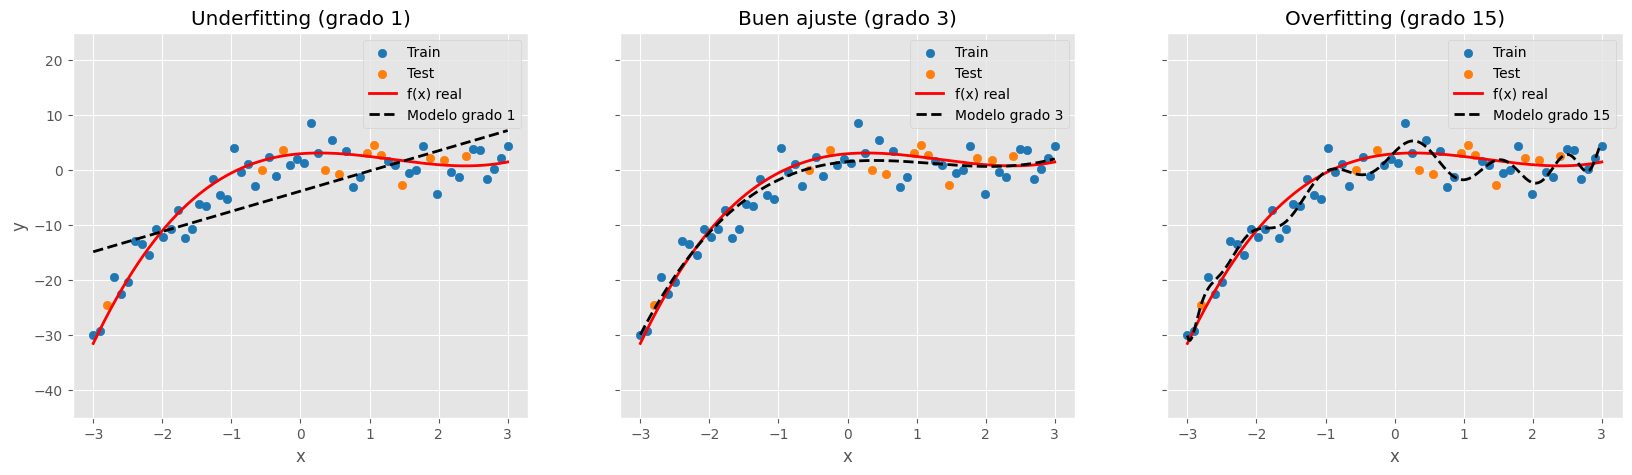

In [18]:
grados_demo = [1, 3, 15]                                   # grados que vamos a mostrar
titulos = ['Underfitting (grado 1)', 'Buen ajuste (grado 3)', 'Overfitting (grado 15)']  # título de cada panel
x_plot = np.linspace(-3, 3, 300)                           # malla fina de x para dibujar curvas suaves

fig, axs = plt.subplots(1, 3, figsize=(20, 5), sharey=True)    # 3 gráficos en una fila, comparten eje y

for ax, g, t in zip(axs, grados_demo, titulos):            # recorre cada grado con su título y su eje
    coef = np.polyfit(x_train, y_train, deg=g)             # ajusta un polinomio de grado g SOLO con datos de train
    y_curva = np.polyval(coef, x_plot)                     # evalúa el polinomio ajustado en la malla fina

    ax.scatter(x_train, y_train, c='tab:blue', label='Train')   # puntos de entrenamiento
    ax.scatter(x_test, y_test, c='tab:orange', label='Test')    # puntos de prueba
    ax.plot(x_plot, f_verdadera(x_plot), 'r-', lw=2, label='f(x) real')   # función verdadera
    ax.plot(x_plot, y_curva, 'k--', lw=2, label=f'Modelo grado {g}')      # modelo ajustado
    ax.set_ylim(-45, 25)                                   # límites del eje y para que la curva no se salga del gráfico
    ax.set_title(t)                                        # título del panel
    ax.set_xlabel('x')                                     # etiqueta eje x
    ax.legend()                                            # leyenda

axs[0].set_ylabel('y')                                     # etiqueta del eje y solo en el primer panel
plt.show()                                                 # muestra los tres gráficos

### ¿Cuál es el mejor grado? Miremos el error en train y en test

Probamos **todos los grados de 1 a 15** y calculamos el **MSE** (error cuadrático medio) en ambos conjuntos.

- El **MSE de train** siempre baja al aumentar el grado: un modelo más flexible se ajusta mejor a lo que ya vio.
- El **MSE de test** baja hasta cierto punto y después **vuelve a subir**: ahí empieza el overfitting.

El mejor modelo es el que tiene **el menor error de test**.

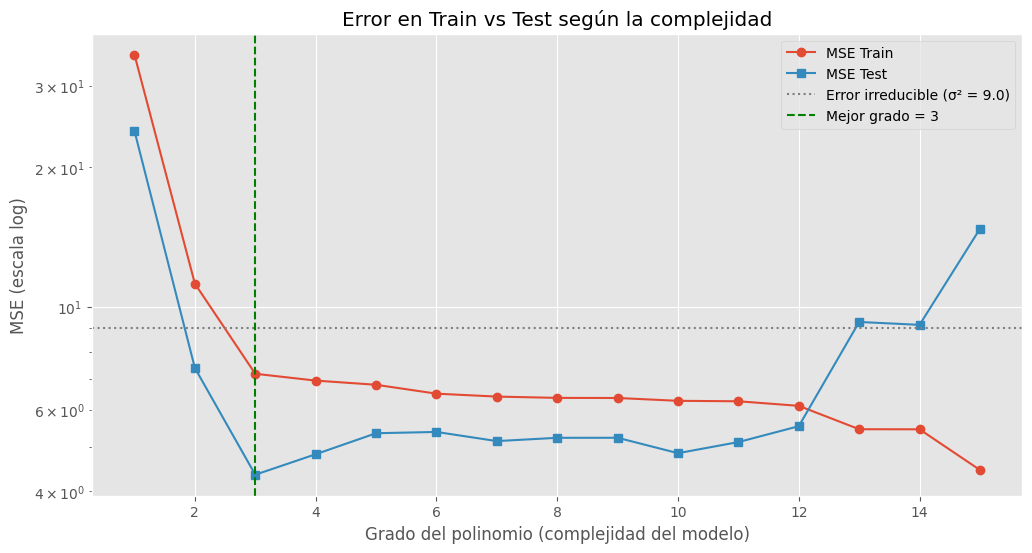

Mejor grado según el MSE de test: 3


In [19]:
grados = range(1, 16)       # grados a evaluar: 1, 2, ..., 15
train_mse = []              # lista para guardar el error en train de cada grado
test_mse = []               # lista para guardar el error en test de cada grado

for g in grados:                                            # recorre cada grado
    coef = np.polyfit(x_train, y_train, deg=g)              # ajusta el polinomio con datos de train
    y_train_pred = np.polyval(coef, x_train)                # predicciones sobre train
    y_test_pred = np.polyval(coef, x_test)                  # predicciones sobre test (datos no vistos)
    train_mse.append(mean_squared_error(y_train, y_train_pred))  # guarda MSE de train
    test_mse.append(mean_squared_error(y_test, y_test_pred))     # guarda MSE de test

mejor_grado = list(grados)[int(np.argmin(test_mse))]        # grado con menor MSE de test (argmin da la posición; la convertimos en grado)

fig = plt.figure(figsize=(12, 6))                                           # nueva figura
plt.plot(grados, train_mse, 'o-', label='MSE Train')                        # curva del error de entrenamiento
plt.plot(grados, test_mse, 's-', label='MSE Test')                          # curva del error de prueba
plt.axhline(SIGMA**2, color='gray', ls=':', label=f'Error irreducible (σ² = {SIGMA**2:.1f})')  # piso teórico del error
plt.axvline(mejor_grado, color='green', ls='--', label=f'Mejor grado = {mejor_grado}')         # marca el mejor grado
plt.yscale('log')                                                           # escala log: el error explota con grados altos
plt.xlabel('Grado del polinomio (complejidad del modelo)')                  # eje x
plt.ylabel('MSE (escala log)')                                              # eje y
plt.title('Error en Train vs Test según la complejidad')                    # título
plt.legend()                                                                # leyenda
plt.show()                                                                  # muestra el gráfico

print("Mejor grado según el MSE de test:", mejor_grado)                     # imprime el grado óptimo (no el índice)

**¿Cómo leer este gráfico?**

- A la izquierda (grados 1-2), ambos errores son **altos**: el modelo es demasiado simple, hay **alto bias**.
- Cerca del grado 3, el error de test alcanza su mínimo y se acerca al **error irreducible** ($\sigma^2 = 9$).
  Es el punto de **complejidad óptima**.
- A la derecha, el error de train sigue bajando pero el de test **se dispara**. Esa brecha es la
  **alta varianza** (overfitting).

> Nota: al ser pocos datos y con ruido aleatorio, el mínimo puede caer en un grado cercano a 3 (por ejemplo 3, 4 o 5)
> y no exactamente en 3. Eso también es una lección: con pocos datos el ruido puede confundir la elección.

### Descomponiendo el error: Bias² + Varianza + Ruido

Hasta ahora usamos **una sola muestra** de datos. Para medir sesgo y varianza de verdad hay que
preguntarse: *¿qué pasaría si entrenara el mismo tipo de modelo con muchas muestras distintas?*

El procedimiento (lo que hace internamente `bias_variance_decomp` de mlxtend):

1. Generamos **200 conjuntos de entrenamiento distintos** (misma función, ruido distinto).
2. Para cada grado, ajustamos un modelo en cada conjunto y predecimos sobre una malla fija de $x$.
3. Calculamos:
   - **Bias²**: qué tan lejos está la **predicción promedio** de la función real $f(x)$.
   - **Varianza**: cuánto **cambian las predicciones** de un modelo a otro.
   - **Ruido**: $\sigma^2$, constante.

$$ Error\ esperado \approx Bias^2 + Varianza + \sigma^2 $$

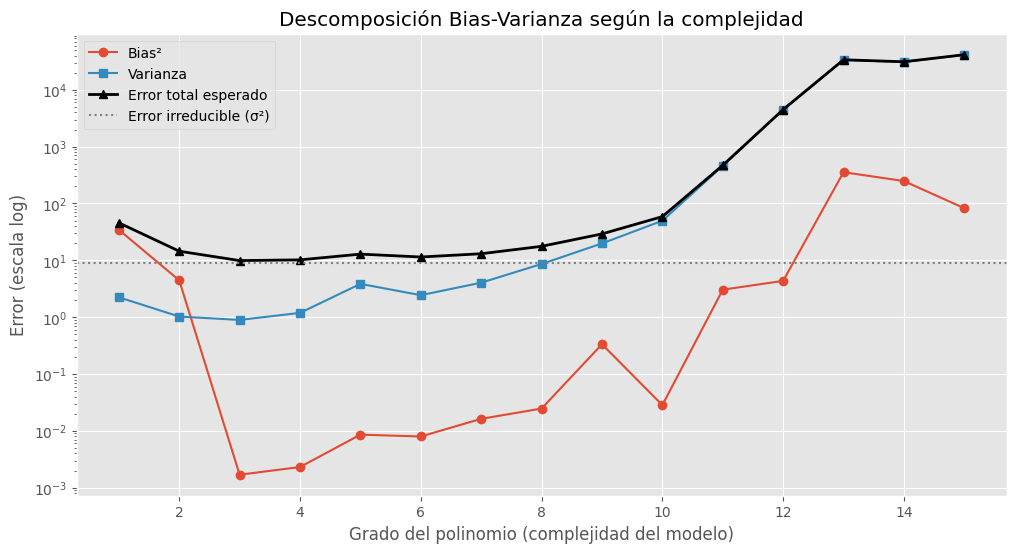

Grado con menor error total esperado: 3


In [20]:
n_rep = 200                                  # cantidad de conjuntos de entrenamiento distintos a simular
n_train = 48                                 # tamaño de cada conjunto de entrenamiento
x_eval = np.linspace(-3, 3, 100)             # malla fija de puntos donde se compararán las predicciones
f_eval = f_verdadera(x_eval)                 # valor real de la función en esa malla
grados_bv = range(1, 16)                     # grados a evaluar

bias2_lista = []                             # aquí se guarda el bias² de cada grado
var_lista = []                               # aquí se guarda la varianza de cada grado

for g in grados_bv:                                          # recorre cada grado
    preds = np.empty((n_rep, len(x_eval)))                   # matriz: una fila de predicciones por cada repetición

    for r in range(n_rep):                                   # repite el experimento n_rep veces
        xs = np.random.uniform(-3, 3, n_train)               # nuevo conjunto de x aleatorios
        ys = f_verdadera(xs) + np.random.normal(0, SIGMA, n_train)  # nuevos y = f(x) + ruido distinto
        coef = np.polyfit(xs, ys, deg=g)                     # ajusta el polinomio de grado g a esta muestra
        preds[r, :] = np.polyval(coef, x_eval)               # guarda sus predicciones en la malla fija

    pred_media = preds.mean(axis=0)                          # predicción promedio de los 200 modelos en cada punto
    bias2 = np.mean((pred_media - f_eval) ** 2)              # bias²: distancia² entre predicción promedio y verdad
    varianza = np.mean(preds.var(axis=0))                    # varianza: dispersión de las predicciones entre modelos

    bias2_lista.append(bias2)                                # guarda bias² del grado g
    var_lista.append(varianza)                               # guarda varianza del grado g

bias2_arr = np.array(bias2_lista)                            # convierte a array para poder sumar
var_arr = np.array(var_lista)                                # idem
error_total = bias2_arr + var_arr + SIGMA**2                 # error esperado = bias² + varianza + ruido

plt.figure(figsize=(12, 6))                                              # nueva figura
plt.plot(grados_bv, bias2_arr, 'o-', label='Bias²')                      # curva de bias²
plt.plot(grados_bv, var_arr, 's-', label='Varianza')                     # curva de varianza
plt.plot(grados_bv, error_total, 'k^-', lw=2, label='Error total esperado')  # suma de los tres componentes
plt.axhline(SIGMA**2, color='gray', ls=':', label='Error irreducible (σ²)')   # piso del error
plt.yscale('log')                                                        # escala log por la explosión de la varianza
plt.xlabel('Grado del polinomio (complejidad del modelo)')               # eje x
plt.ylabel('Error (escala log)')                                         # eje y
plt.title('Descomposición Bias-Varianza según la complejidad')           # título
plt.legend()                                                             # leyenda
plt.show()                                                               # muestra el gráfico

print("Grado con menor error total esperado:", list(grados_bv)[int(np.argmin(error_total))])  # grado óptimo teórico

**Conclusiones del experimento**

- **Bias²** es enorme con grados 1 y 2 (modelo demasiado simple) y se vuelve casi **cero desde el grado 3**,
  porque el modelo ya tiene la forma de la función real.
- **Varianza** es muy baja con modelos simples y **crece rápidamente** con grados altos: cada muestra de
  entrenamiento produce un polinomio muy distinto.
- **Error total** tiene forma de "U": el mínimo se da donde Bias² y Varianza están **balanceados**
  (alrededor del grado 3). Ese es el **compromiso Bias-Variance**.
- El **error irreducible** ($\sigma^2$) es un piso: ni el mejor modelo puede bajar de ahí.

**Qué hacer en cada caso (conecta con la unidad de Evaluación y Validación):**

| Síntoma | Diagnóstico | Acción |
|---|---|---|
| Error alto en train y test | Alto bias | Aumentar complejidad, agregar variables polinómicas, reducir regularización |
| Error bajo en train, alto en test | Alta varianza | Simplificar, regularizar (Ridge/Lasso), conseguir más datos |

> **Idea clave:** en un caso real no conocemos la función verdadera, por eso en la práctica usamos
> **validación cruzada** y **curvas de aprendizaje** para encontrar ese punto óptimo.

## Ejemplo en clasificación

In [21]:
!pip install --user mlxtend

In [22]:
from mlxtend.evaluate import bias_variance_decomp
from sklearn.tree import DecisionTreeClassifier
from mlxtend.data import iris_data
from sklearn.model_selection import train_test_split


X, y = iris_data()
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.3,
                                                    random_state=123,
                                                    shuffle=True,
                                                    stratify=y)



tree = DecisionTreeClassifier(random_state=123)

avg_expected_loss, avg_bias, avg_var = bias_variance_decomp(
        tree, X_train, y_train, X_test, y_test,
        loss='0-1_loss',
        random_seed=123)

print('Average expected loss: %.3f' % avg_expected_loss)
print('Average bias: %.3f' % avg_bias)
print('Average variance: %.3f' % avg_var)

Average expected loss: 0.062
Average bias: 0.022
Average variance: 0.040


# Análisis del ERROR

## ¿Cómo tratamos el bias/variance?

## Hechos

![imagen.png](attachment:imagen.png)


### Mas datos tiende a mejorar la perfomance de casi cualquier algoritmo

### Mas características tiene a mejorar la perfomance de casi cualquier algoritmo

obviamente hablamos de datos y caraterísticas de buena calidad, en condiciones de ser procesadas por los algoritmos



### Enfoque recomendado


1- Iniciar con un modelo simple, rápido de implementar.

2- Agregar un set para hacer cross validation y testear de ésta forma. Esto implica implementar métodos de Resampling, Emsebling, Boosting, Bagging.

3- Dibijar la curva de aprendizaje para determinar si se necesitan mas datos, mas características, etc.
Repasando: mas datos debería disminuir el bias, mas características debería disminuir la varianza.

4- Analizar el error.

## Posibles tratamientos con bias y varianza alta



|High Bias |	High Varianza |
| :--| :-- |
|intentar obtener caractedísticas adicionales| obtener mas datos de entrenamiento|
| 	 intentar agregar características polinomiales| 	intentar con un conjunto de características mas pequeño - Reducción dimencional|
|achicar $\lambda$ (lambda: coeficiente de regularización) | 	agrandar $\lambda$ (lambda: coeficiente de regularización)|




## Lo que falta:

1- técnicas de regularización:

2-

## Referencias

https://www.kaggle.com/code/residentmario/bias-variance-tradeoff/notebook


http://scott.fortmann-roe.com/docs/BiasVariance.html



